![Python Banner](../../Image/05_02_meta_learners.png)


# 2.6 Doubly Robust Learners

Doubly robust (DR) learning estimates heterogeneous treatment effects (CATE) in observational studies by combining **treatment-specific outcome models** and **propensity scores**, then fitting a **final-stage** model for $\tau(X)$. This notebook gives the statistical background, contrasts DR learning with **double machine learning (DML)**, and shows **PyCausalML** implementations: DR meta-learners live in **``pycausalml.meta_learners``** (`DRLearner` and special cases); DML estimators live in **``pycausalml.double_machine_learning``** (`DMLearner`, `LinearDML`, `CausalForestDML`, and related constructors).


## Overview

The **Doubly Robust Learner** (DR-Learner) is a meta-learner for estimating the Conditional Average Treatment Effect from observational data with discrete treatments. It belongs to the family of **doubly robust** estimators: by combining an outcome model with a propensity score model, it remains consistent if *either* — but not necessarily both — is correctly specified. When both nuisance models converge at sufficiently fast rates, the DR-Learner achieves $\sqrt{n}$-consistency and asymptotic normality for the CATE, enabling valid confidence intervals and hypothesis tests that are not available from standard meta-learners.

---

### Setting and Identification

The DR-Learner applies when:

- The treatment $T$ is **discrete**, with $T \in \{0, 1, \dots, K-1\}$ and a designated reference arm $T = 0$.
- Confounders are **observed** — possibly high-dimensional — in the covariate vector $(X, W)$.
- **Unconfoundedness** holds: $Y(t) \perp T \mid X, W$ for all $t$.

The target estimand for each active arm $t \geq 1$ is the contrast against control:

$$\tau_t(x) = \mathbb{E}[Y(t) - Y(0) \mid X = x]$$

---

### Nuisance Estimation with Cross-Fitting

The DR-Learner requires two nuisance objects, both estimated using flexible ML algorithms:

- **Arm-specific outcome models**: $\hat{g}_t(X, W) \approx \mathbb{E}[Y \mid T = t, X, W]$ for each arm $t$.
- **Propensity scores**: $\hat{p}_t(X, W) \approx P(T = t \mid X, W)$ for each arm $t$.

A critical implementation detail is **cross-fitting** (also called sample splitting), which **PyCausalML** performs with 3-fold rotation by default, following Kennedy (2020). The sample is partitioned into $K$ folds; for each fold, the nuisance models are trained on the remaining $K-1$ folds and used to construct pseudo-outcomes on the held-out fold. This rotation ensures that the observations used to fit the nuisance models are never the same ones used to construct pseudo-outcomes or fit the final CATE model. Without cross-fitting, reusing the same observations for all three stages introduces optimistic bias that invalidates inference.

---

### DR Pseudo-Outcomes

Using the estimated nuisance functions, a **doubly robust pseudo-outcome** is constructed for each unit and each contrast $t$ vs. $0$:

$$\hat{\phi}_i^t = \hat{g}_t(X_i, W_i) - \hat{g}_0(X_i, W_i) + \frac{\mathbf{1}[T_i = t]\left(Y_i - \hat{g}_t(X_i, W_i)\right)}{\hat{p}_t(X_i, W_i)} - \frac{\mathbf{1}[T_i = 0]\left(Y_i - \hat{g}_0(X_i, W_i)\right)}{\hat{p}_0(X_i, W_i)}$$

The pseudo-outcome $\hat{\phi}_i^t$ is an unbiased unit-level estimate of $\tau_t(X_i)$ under the doubly robust identification condition. Its key property is that the bias of $\hat{\phi}_i^t$ as an estimator of the true effect depends on the **product** of the outcome model error and the propensity score error — rather than on either error alone. This means that moderate misspecification of one nuisance function is tolerable provided the other is well-estimated, a substantially weaker requirement than demanding both to be correct simultaneously.

---

### Final Stage: CATE Estimation

The CATE function $\tau_t(x)$ is recovered by regressing the pseudo-outcomes $\hat{\phi}_i^t$ on the covariates $X_i$:

$$\hat{\tau}_t = \arg\min_f \sum_{i} \left(\hat{\phi}_i^t - f(X_i)\right)^2$$

Any regression algorithm may be used for this final stage. The choice determines the structural assumptions imposed on $\tau_t(x)$, the dimensionality that can be handled, and the type of inference available. **PyCausalML** provides four specialized implementations that differ along exactly these dimensions.

---

### DR-Learner Variants in PyCausalML

#### `DRLearner` (Base Class)

The base `DRLearner` imposes no structural assumptions on the CATE function. Any scikit-learn-compatible regressor or classifier may be used for the nuisance models, and any regressor may be used for the final stage. This makes it a fully general-purpose estimator suitable for exploratory analysis when the form of treatment effect heterogeneity is unknown. Valid confidence intervals are available when cross-fitting is enabled, subject to the convergence conditions of the chosen base learners.

**Best for**: Exploratory CATE estimation with custom model choices; no prior assumptions on functional form.

#### `LinearDRLearner`

`LinearDRLearner` specializes the final stage to an **unregularized linear regression** of the pseudo-outcomes on $X$, imposing the assumption that

$$\tau_t(x) = x^\top \beta_t$$

The linearity assumption enables asymptotic normality-based inference: closed-form standard errors, confidence intervals, and p-values for the coefficients $\hat{\beta}_t$ are available without resampling. This is the most interpretable variant and the most statistically efficient when the linearity assumption holds, but it fails — both in estimation accuracy and in inference validity — when the true CATE is nonlinear or when the number of features approaches the sample size.

**Best for**: Low-dimensional settings ($p \ll n$) where linear treatment effect heterogeneity is plausible and coefficient-level interpretability is required.

#### `SparseLinearDRLearner`

`SparseLinearDRLearner` extends the linear final stage to **high-dimensional settings** where the number of features may equal or exceed the sample size. It uses a **debiased Lasso** ($\ell_1$-regularized regression with a post-regularization debiasing correction) in the final stage, which simultaneously performs feature selection and produces asymptotically normal coefficient estimates under a sparsity assumption on $\beta_t$. The debiasing step is essential: naive Lasso estimates are shrunk toward zero in a way that invalidates standard inference, and the correction removes this shrinkage bias for the purpose of hypothesis testing.

**Best for**: High-dimensional settings ($p \geq n$) where treatment effect heterogeneity is driven by a sparse subset of covariates and both feature selection and valid inference are required.

#### `ForestDRLearner`

`ForestDRLearner` uses a **subsampled honest random forest** in the final stage, replacing the linear model with a fully nonparametric estimator. Honesty — the use of separate subsamples for tree construction and leaf-level estimation — is a key property that prevents the forest from overfitting the pseudo-outcomes and ensures asymptotic validity of the resulting estimates. Confidence intervals are constructed via the **Bootstrap-of-Little-Bags (BLB)** procedure, a computationally efficient resampling method for variance estimation in subsampled forests.

**Best for**: Moderate-to-high dimensional settings with complex, nonlinear treatment effect heterogeneity where no linearity or sparsity is assumed and forest-based uncertainty quantification is acceptable.

#### `XGBDRLearner`

`XGBDRLearner` uses **XGBoost** gradient boosting in the final stage. It can capture complex interactions and high-order nonlinearities in $\tau_t(x)$ and typically achieves strong predictive performance. The trade-off is inferential: formal confidence intervals for the CATE function are not directly available from gradient boosting, and uncertainty quantification requires approximations such as SHAP-based sensitivity analysis or permutation importance.

**Best for**: Settings where predictive accuracy of the CATE is the primary objective and approximate rather than formal uncertainty quantification is acceptable.

---

### Variant Comparison

| Aspect | `DRLearner` | `LinearDRLearner` | `SparseLinearDRLearner` | `ForestDRLearner` |
|--------|-------------|-------------------|-------------------------|-------------------|
| **Final stage** | Any regressor | Unregularized OLS | Debiased Lasso | Honest random forest |
| **CATE assumption** | None | Linear in $X$ | Linear, sparse in $X$ | None (nonparametric) |
| **Dimensionality** | Depends on base learner | $p \ll n$ | $p \geq n$ supported | Moderate-to-high |
| **Inference** | Valid with cross-fitting | Asymptotic normality | Asymptotic normality (debiased) | BLB resampling |
| **Interpretability** | Low–high (model-dependent) | High (coefficients) | High (sparse coefficients) | Low |
| **Best for** | Exploratory, custom pipelines | Low-dim linear effects | High-dim sparse effects | Nonlinear effects |

---

### DR-Learner vs. Double Machine Learning (DML)

The DR-Learner and the **Double Machine Learning** estimator (DML; Chernozhukov et al., 2018) share the same high-level goals — debiased CATE estimation under high-dimensional confounding — but differ in their construction, treatment scope, and robustness properties.

The DR-Learner constructs arm-specific outcome models $\hat{g}_t(X, W)$ and uses inverse-propensity weighting to debias counterfactual predictions. The doubly robust property provides robustness to misspecification of *one* nuisance component. DML instead residualizes both the outcome and the treatment against their conditional expectations — $\tilde{Y} = Y - \hat{\mathbb{E}}[Y \mid X, W]$ and $\tilde{T} = T - \hat{\mathbb{E}}[T \mid X, W]$ — and regresses $\tilde{Y}$ on $\tilde{T}$ and covariates. This Neyman-orthogonal construction means that bias in the final CATE estimate depends on the *product* of errors in both nuisance models, providing robustness to misspecification of either, but refined inference requires both to converge at adequate rates.

| Aspect | DR-Learner | DML |
|--------|------------|-----|
| **First-stage outcome** | Arm-specific $\hat{g}_t(X, W)$ | Marginal $\hat{\mathbb{E}}[Y \mid X, W]$ (residualized) |
| **Robustness** | Doubly robust (discrete $T$) | Neyman-orthogonal (both nuisances matter for inference) |
| **Treatment types** | Discrete (binary or multi-arm) | Binary, continuous, and multivariate $T$ |
| **PyCausalML entry points** | `DRLearner`, `LinearDRLearner`, … | `DMLearner`, `LinearDML`, `CausalForestDML`, … |

**Prefer the DR-Learner** when the treatment is categorical, arm-specific outcome modeling is natural, and EconML/causalml methodological parity is desired. **Prefer DML** when the treatment is continuous or multivariate, a residualization-based pipeline is preferred, or the `CausalForestDML` combination of DML first stages with `a causal forest` is the target estimator.


## Implementation in Python

PyCausalML fits these doubly robust and double-machine-learning variants with `fit(X, treatment, y)` and `predict(X)`.

| Variant in this notebook | PyCausalML object | Final stage |
|---|---|---|
| Random-forest DR | `DRLearner(learner="rf")` | Random forest of the DR pseudo-outcome |
| Linear DR | `DRLearner(learner="lm")` | OLS of the DR pseudo-outcome |
| Sparse linear DR | Lasso on `dr_scores_` | L1-penalized linear CATE |
| XGBoost DR | `DRLearner(learner="xgb")` | Gradient boosting |
| Linear DML | `LinearDML` | Linear CATE on cross-fit residuals |

`learner` selects the base regressor (`"lm"`, `"rf"`, `"xgb"`, or `"gbr"`). Cross-fitting uses `n_splits`. `average_treatment_effect()` returns a point estimate and a standard error when an influence function is available. For the linear DR-Learner, slopes are the coefficients from regressing the doubly robust pseudo-outcome on `X`.


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
try:
    import pycausalml  # noqa: F401
    import causaldata  # noqa: F401
    import matplotlib  # noqa: F401
    import xgboost  # noqa: F401
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot,boost,shap]",
        "statsmodels", "causaldata",
    ])
print("PyCausalML ready.")

%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path

from pycausalml import (
    DRLearner,
    DomainAdaptationLearner,
    LinearDML,
    RLearner,
    SLearner,
    SparseLinearDML,
    TLearner,
    XLearner,
    explain_cate,
    synthetic_data,
)
from pycausalml.data import make_multiarm_data
from pycausalml.double_machine_learning import CausalForestDML, PartiallyLinearDML

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
N_EST = 25
print("Imported PyCausalML")

def ate_row(name, model, X):
    cate = np.asarray(model.predict(X), dtype=float)
    info = model.average_treatment_effect(X)
    est = float(info["estimate"])
    se = float(info["std.err"])
    if not np.isfinite(se):
        se = float(np.std(cate, ddof=1) / np.sqrt(len(cate)))
        est = float(np.mean(cate))
    return {
        "learner": name,
        "ate": est,
        "se": se,
        "ci_lower": est - 1.96 * se,
        "ci_upper": est + 1.96 * se,
    }

def abs_pct_ate(pred, truth):
    denom = abs(float(np.mean(truth)))
    if denom < 1e-8:
        return np.nan
    return 100.0 * abs(float(np.mean(pred) - np.mean(truth))) / denom

def kl_divergence(pred, truth, bins=15):
    pred = np.asarray(pred, dtype=float)
    truth = np.asarray(truth, dtype=float)
    lo = float(min(pred.min(), truth.min()))
    hi = float(max(pred.max(), truth.max()))
    if not np.isfinite(lo) or hi <= lo:
        return np.nan
    hp, _ = np.histogram(pred, bins=bins, range=(lo, hi))
    hq, _ = np.histogram(truth, bins=bins, range=(lo, hi))
    hp = hp.astype(float) + 1e-3
    hq = hq.astype(float) + 1e-3
    hp /= hp.sum()
    hq /= hq.sum()
    return float(np.sum(hp * np.log(hp / hq)))

def cumulative_gain(y, w, score):
    order = np.argsort(-np.asarray(score, dtype=float))
    y = np.asarray(y, dtype=float)[order]
    w = np.asarray(w)[order]
    n = len(y)
    frac = np.arange(1, n + 1) / n
    gain = np.empty(n)
    for i in range(n):
        ww = w[: i + 1]
        yy = y[: i + 1]
        n1 = int((ww == 1).sum())
        n0 = int((ww == 0).sum())
        gain[i] = 0.0 if n1 == 0 or n0 == 0 else (yy[ww == 1].mean() - yy[ww == 0].mean()) * (i + 1) / n
    return frac, gain

def tutorial_file(name: str) -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        for rel in (
            Path("Tutorials") / "05_02_Meta_Learners" / "data" / name,
            Path("data") / name,
        ):
            path = cand / rel
            if path.is_file():
                return path
    raise FileNotFoundError(name)

rng = np.random.default_rng(42)
n = 1200
X_effect = rng.normal(size=(n, 5))
W_conf = rng.normal(size=(n, 3))
X = np.column_stack([X_effect, W_conf])
logit = -0.15 + 0.7 * W_conf[:, 0] - 0.45 * W_conf[:, 1]
prop = 1 / (1 + np.exp(-logit))
treat = rng.binomial(1, prop)
tau = 1.5 * X_effect[:, 0]
y = 0.4 * X_effect[:, 1] + W_conf[:, 0] + treat * tau + rng.normal(size=n)
feature_names = [f"X{i+1}" for i in range(5)] + [f"W{i+1}" for i in range(3)]
print("n", n, "treatment rate", round(float(treat.mean()), 3), "true ATE", round(float(tau.mean()), 3))
print("Mapping: random-forest DR -> DRLearner(learner='rf'); linear DR -> learner='lm';")
print("sparse DR -> Lasso on the doubly robust pseudo-outcome; XGBoost DR -> learner='xgb'.")

def show_ate(info):
    print(info["learner"])
    numeric = {k: v for k, v in info.items() if isinstance(v, (int, float))}
    print(pd.Series(numeric).round(3).to_string())


PyCausalML ready.


Imported PyCausalML
n 1200 treatment rate 0.463 true ATE -0.046
Mapping: random-forest DR -> DRLearner(learner='rf'); linear DR -> learner='lm';
sparse DR -> Lasso on the doubly robust pseudo-outcome; XGBoost DR -> learner='xgb'.


## Part A: DR Learners with Sythetic Data

First we show examples of the DR learners in {RCausaML}  on a shared synthetic data-generating process (DGP) with a binary treatment and linear CATE.

### Shared simulation: binary treatment

The DGP includes 5 effect modifiers (`X1`–`X5`) and 3 confounders (`W1`–`W3`), with treatment assignment depending on the confounders and the outcome depending on both confounders and the effect modifiers. The true CATE is linear in `X1` only, allowing us to evaluate how well each DR learner captures this structure.


### `ForestDRLearner`: random forest final stage


In [2]:
dr_forest = DRLearner(learner="rf", n_estimators=N_EST, n_splits=2, random_state=42)
dr_forest.fit(X, treat, y, feature_names=feature_names)
show_ate(ate_row("Random-forest DR", dr_forest, X))


Random-forest DR
ate         0.024
se          0.078
ci_lower   -0.128
ci_upper    0.176


Overlap check using fitted propensity:


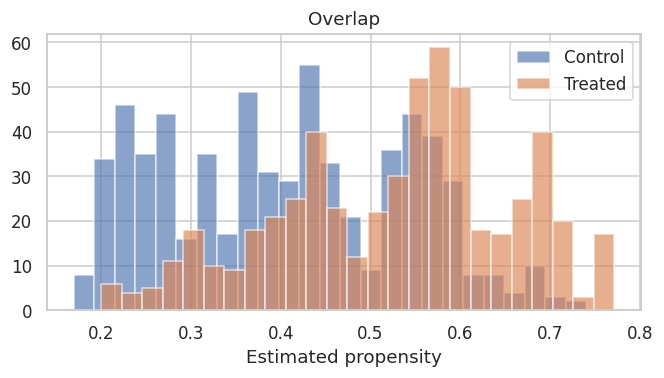

Propensity range 0.17 0.771


In [3]:
from sklearn.ensemble import GradientBoostingClassifier
propensity = GradientBoostingClassifier(n_estimators=N_EST, max_depth=2, random_state=42)
propensity.fit(X, treat)
phat = propensity.predict_proba(X)[:, 1]
fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.hist(phat[treat == 0], bins=25, alpha=0.65, label="Control")
ax.hist(phat[treat == 1], bins=25, alpha=0.65, label="Treated")
ax.set_xlabel("Estimated propensity")
ax.set_title("Overlap")
ax.legend()
fig.tight_layout()
plt.show()
print("Propensity range", round(float(phat.min()), 3), round(float(phat.max()), 3))


### `LinearDRLearner`: OLS final stage and coefficients


In [4]:
from sklearn.linear_model import LinearRegression
dr_lin = DRLearner(learner="lm", n_estimators=N_EST, random_state=42)
dr_lin.fit(X, treat, y, feature_names=feature_names)
coef = LinearRegression().fit(X, dr_lin.dr_scores_)
show_ate(ate_row("Linear DR", dr_lin, X))
print("Final-stage slopes (true effect loads on X1 only)")
print(pd.Series(coef.coef_, index=feature_names).round(3).to_string())


Linear DR
ate        -0.068
se          0.074
ci_lower   -0.212
ci_upper    0.076
Final-stage slopes (true effect loads on X1 only)
X1    1.407
X2   -0.055
X3   -0.031
X4   -0.020
X5    0.053
W1   -0.027
W2    0.041
W3   -0.056


The simulation is linear in `X1` only; other columns enter through confounding and may appear with small estimated slopes.

### `SparseLinearDRLearner`: Lasso-style final stage


### `XGBDRLearner` (optional)

Requires the **xgboost** package.


In [5]:
dr_xgb = DRLearner(learner="xgb", n_estimators=N_EST, random_state=42)
dr_xgb.fit(X, treat, y, feature_names=feature_names)
show_ate(ate_row("XGBoost DR", dr_xgb, X))


XGBoost DR
ate         0.042
se          0.079
ci_lower   -0.114
ci_upper    0.198


### Generic `DRLearner`: mix learners across stages

Example: flexible nuisances with a **linear** CATE surface.


In [6]:
dr_mixed = DRLearner(learner="gbr", n_estimators=N_EST, random_state=42)
dr_mixed.fit(X, treat, y, feature_names=feature_names)
show_ate(ate_row("Gradient-boosting DR", dr_mixed, X))
print("Nuisance outcome models use the same learner; the propensity score is cross-fit with gradient boosting.")


Gradient-boosting DR
ate         0.059
se          0.081
ci_lower   -0.100
ci_upper    0.219
Nuisance outcome models use the same learner; the propensity score is cross-fit with gradient boosting.


### `LinearDML` (DML baseline for the comparison table)


In [7]:
from sklearn.linear_model import Lasso
dml_lin = LinearDML(discrete_treatment=True, n_estimators=N_EST, model_y="gbr", random_state=42)
dml_lin.fit(X, treat, y, feature_names=feature_names)
sparse = Lasso(alpha=0.05, max_iter=5000).fit(X, dr_lin.dr_scores_)
print("Linear DML", {k: round(float(v), 3) for k, v in dml_lin.average_treatment_effect().items() if np.ndim(v) == 0})
print("Sparse DR slopes")
print(pd.Series(sparse.coef_, index=feature_names).round(3).to_string())


Linear DML {'estimate': 0.049, 'std.err': 0.07, 'ci_lower': -0.088, 'ci_upper': 0.186}
Sparse DR slopes
X1    1.359
X2   -0.009
X3   -0.000
X4   -0.000
X5    0.004
W1   -0.000
W2    0.000
W3   -0.011


### Quick comparison on this DGP


In [8]:
rows = [ate_row(label, model, X) for label, model in (
    ("Random-forest DR", dr_forest),
    ("Linear DR", dr_lin),
    ("XGBoost DR", dr_xgb),
    ("Gradient-boosting DR", dr_mixed),
)]
rows.append({
    "learner": "Linear DML",
    "ate": dml_lin.average_treatment_effect()["estimate"],
    "se": dml_lin.average_treatment_effect()["std.err"],
    "ci_lower": dml_lin.average_treatment_effect()["ci_lower"],
    "ci_upper": dml_lin.average_treatment_effect()["ci_upper"],
})
out = pd.DataFrame(rows)
out["true_ate"] = float(tau.mean())
print(out.round(3).to_string(index=False))


             learner    ate    se  ci_lower  ci_upper  true_ate
    Random-forest DR  0.024 0.078    -0.128     0.176    -0.046
           Linear DR -0.068 0.074    -0.212     0.076    -0.046
          XGBoost DR  0.042 0.079    -0.114     0.198    -0.046
Gradient-boosting DR  0.059 0.081    -0.100     0.219    -0.046
          Linear DML  0.049 0.070    -0.088     0.186    -0.046


## Part B: Use case — abortion data

We apply the same meta-learner API to the **abortion** dataset from ``causaldata`` (state–year units; outcome **lnr**, logged gonorrhea rate among 15–19 year olds; treatment is **early repeal** of abortion prohibition). We load the raw table with `load_causaldata("abortion")$data`, restrict to ages 15–19, and encode treatment as a **binary factor** with levels `"Control"` (no early repeal) and `"Treated"` (early repeal). Internally, **PyCausalML** maps that factor to numeric codes (1 = Control, 2 = Treated with `levels = c("Control", "Treated")`), so every meta-learner below is constructed with `control_name = 1L`.

### Data


### Data Preparation


Abortion dataset loaded. Columns: ['fip', 'age', 'race', 'year', 'sex', 'totpop', 'ir', 'crack', 'alcohol', 'income', 'ur', 'poverty', 'repeal', 'acc', 'wht', 'male', 'lnr', 't', 'younger', 'fa', 'pi', 'bf15']
::
    Number of observations - 19584
    Number of variables - 22
    Variables name definitions::
            fip - State FIPS code
            age - Age in years
            race - Race: 1 = white, 2 = black
            year - Year
            t - Year but on a different scale
            sex - Sex: 1 = male, 2 = female
            totpop - Total population
            ir - Incarcerated Males per 100,000
            crack - Crack index
            alcohol - Alcohol consumption per capita
            income - Real income per capita
            ur - State unemployment rate
            poverty - Poverty rate
            repeal - In a state with an early repeal of abortion prohibition
            acc - AIDS mortality per 100,000 cumulative in t, t-1, t-2, t-3
            wht - Whi

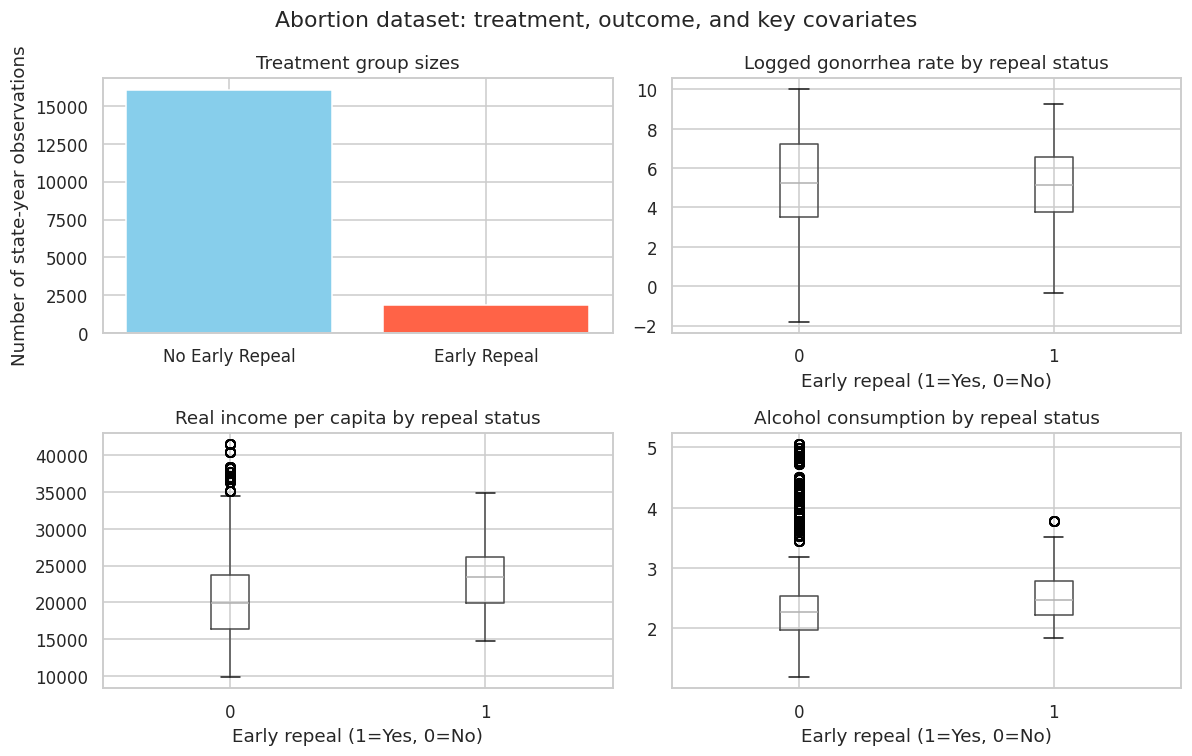

Covariates used: ['fip', 'age', 'race', 'year', 'sex', 'totpop', 'ir', 'crack', 'alcohol', 'income', 'ur', 'poverty', 'acc', 'wht', 'male', 't', 'younger', 'pi', 'bf15']
n = 17921  treated = 1854
Training set size: 14337
Test set size: 3584


In [9]:
from causaldata import abortion

abortion_df = abortion.load_pandas().data.copy()
print("Abortion dataset loaded. Columns:", list(abortion_df.columns))
print(abortion.NOTE)
print(abortion.DESCRLONG)
print(abortion.SOURCE)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
plot_df = abortion_df.dropna(subset=["lnr"]).copy()
counts = plot_df["repeal"].value_counts().sort_index()
axes[0, 0].bar(["No Early Repeal", "Early Repeal"], counts.to_numpy(), color=["skyblue", "tomato"])
axes[0, 0].set_title("Treatment group sizes")
axes[0, 0].set_ylabel("Number of state-year observations")
plot_df.boxplot(column="lnr", by="repeal", ax=axes[0, 1])
axes[0, 1].set_title("Logged gonorrhea rate by repeal status")
axes[0, 1].set_xlabel("Early repeal (1=Yes, 0=No)")
plot_df.boxplot(column="income", by="repeal", ax=axes[1, 0])
axes[1, 0].set_title("Real income per capita by repeal status")
axes[1, 0].set_xlabel("Early repeal (1=Yes, 0=No)")
plot_df.boxplot(column="alcohol", by="repeal", ax=axes[1, 1])
axes[1, 1].set_title("Alcohol consumption by repeal status")
axes[1, 1].set_xlabel("Early repeal (1=Yes, 0=No)")
plt.suptitle("Abortion dataset: treatment, outcome, and key covariates")
fig.tight_layout()
plt.show()

feature_names = [
    c for c in plot_df.columns
    if c not in ("lnr", "repeal") and plot_df[c].notna().all()
]
X_ab = plot_df[feature_names].to_numpy(dtype=float)
Y_ab = plot_df["lnr"].to_numpy(dtype=float)
W_ab = plot_df["repeal"].to_numpy(dtype=int)
print("Covariates used:", feature_names)
print("n =", len(Y_ab), " treated =", int(W_ab.sum()))

rng_ab = np.random.default_rng(333)
n_ab = len(Y_ab)
train_idx = rng_ab.choice(n_ab, size=round(0.8 * n_ab), replace=False)
test_idx = np.setdiff1d(np.arange(n_ab), train_idx)
X_ab_tr, X_ab_te = X_ab[train_idx], X_ab[test_idx]
Y_ab_tr, Y_ab_te = Y_ab[train_idx], Y_ab[test_idx]
W_ab_tr, W_ab_te = W_ab[train_idx], W_ab[test_idx]
print("Training set size:", len(Y_ab_tr))
print("Test set size:", len(Y_ab_te))


### Data split


We **fit** each learner on the training rows and report (**i**) **mean predicted CATE** on the **held-out test** covariates `X_ab_te` (heterogeneity summary on new units) and (**ii**) **ATE** on the **training** sample using `estimate_ate(..., pretrain = TRUE)` (point estimate and normal approx. interval from the DR learner’s `ate_alpha`).

### `ForestDRLearner`


In [10]:
dr_models = {}
for label, kwargs in (
    ("Random-forest DR", dict(learner="rf")),
    ("Linear DR", dict(learner="lm")),
    ("XGBoost DR", dict(learner="xgb")),
):
    model = DRLearner(n_estimators=N_EST, n_splits=2, random_state=333, **kwargs)
    model.fit(X_ab_tr, W_ab_tr, Y_ab_tr, feature_names=feature_names)
    dr_models[label] = model
dml_ab = LinearDML(discrete_treatment=True, n_estimators=N_EST, model_y="gbr", random_state=333)
dml_ab.fit(X_ab_tr, W_ab_tr, Y_ab_tr, feature_names=feature_names)
sparse_ab = Lasso(alpha=0.02, max_iter=5000).fit(X_ab_tr, dr_models["Linear DR"].dr_scores_)
print("Sparse DR nonzero covariates", int(np.sum(np.abs(sparse_ab.coef_) > 1e-6)))


Sparse DR nonzero covariates 13


### `LinearDRLearner`


### `SparseLinearDRLearner`


### `XGBDRLearner`

Runs when **xgboost** is installed; otherwise a single table row records that it was skipped.


### Comparison (abortion, train / test split)


In [11]:
rows = []
for label, model in dr_models.items():
    row = ate_row(label, model, X_ab_tr)
    row["mean_cate_test"] = float(np.mean(model.predict(X_ab_te)))
    rows.append(row)
info = dml_ab.average_treatment_effect()
rows.append({
    "learner": "Linear DML",
    "ate": info["estimate"],
    "se": info["std.err"],
    "ci_lower": info["ci_lower"],
    "ci_upper": info["ci_upper"],
    "mean_cate_test": float(np.mean(dml_ab.predict(X_ab_te))),
})
print(pd.DataFrame(rows).round(3).to_string(index=False))


         learner    ate    se  ci_lower  ci_upper  mean_cate_test
Random-forest DR -0.177 0.013    -0.201    -0.152          -0.164
       Linear DR -0.050 0.014    -0.078    -0.023          -0.041
      XGBoost DR -0.074 0.014    -0.101    -0.047          -0.067
      Linear DML -0.598 0.033    -0.663    -0.533          -0.604


### Visualize predicted CATE distribution on training split


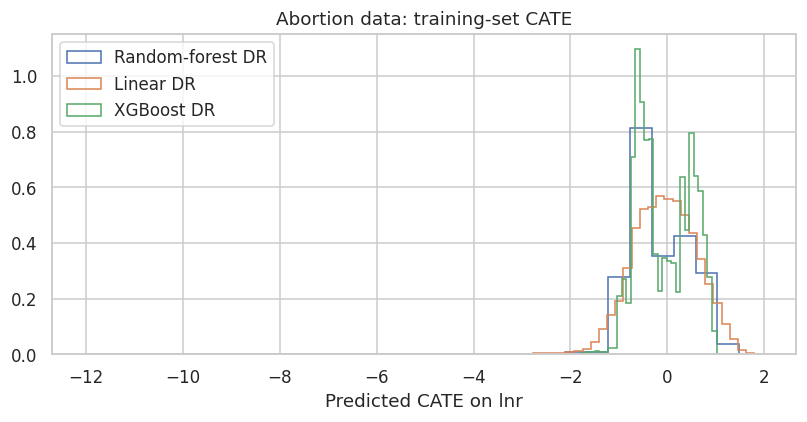

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for label, model in dr_models.items():
    ax.hist(model.predict(X_ab_tr), bins=30, histtype="step", density=True, label=label)
ax.set_xlabel("Predicted CATE on lnr")
ax.set_title("Abortion data: training-set CATE")
ax.legend()
fig.tight_layout()
plt.show()


### SHAP for predicted CATE (abortion, training subsample)


In [13]:
ab_exp = explain_cate(
    dr_models["Linear DR"], X_ab_tr, max_samples=24, n_permutations=6,
    feature_names=feature_names, random_state=333,
)
print(pd.Series(ab_exp.importance(), index=ab_exp.feature_names).round(3).sort_values(ascending=False).to_string())


race       0.273
wht        0.273
totpop     0.243
ur         0.207
poverty    0.194
ir         0.180
income     0.148
age        0.136
year       0.131
t          0.131
fip        0.085
acc        0.070
alcohol    0.058
younger    0.040
sex        0.028
male       0.028
crack      0.014
pi         0.008
bf15       0.000


### Visualize SHAP with beeswarm and waterfall plots for one DR learner (LinearDRLearner)


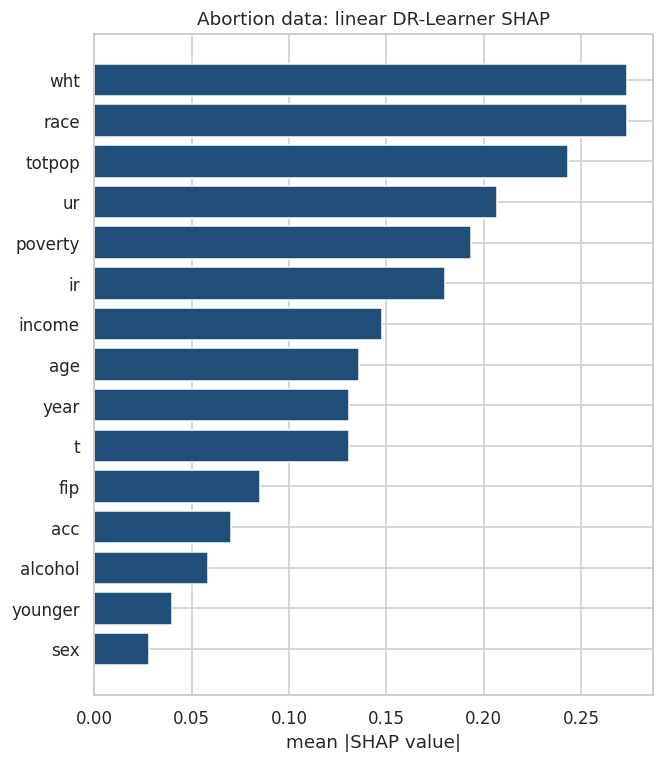

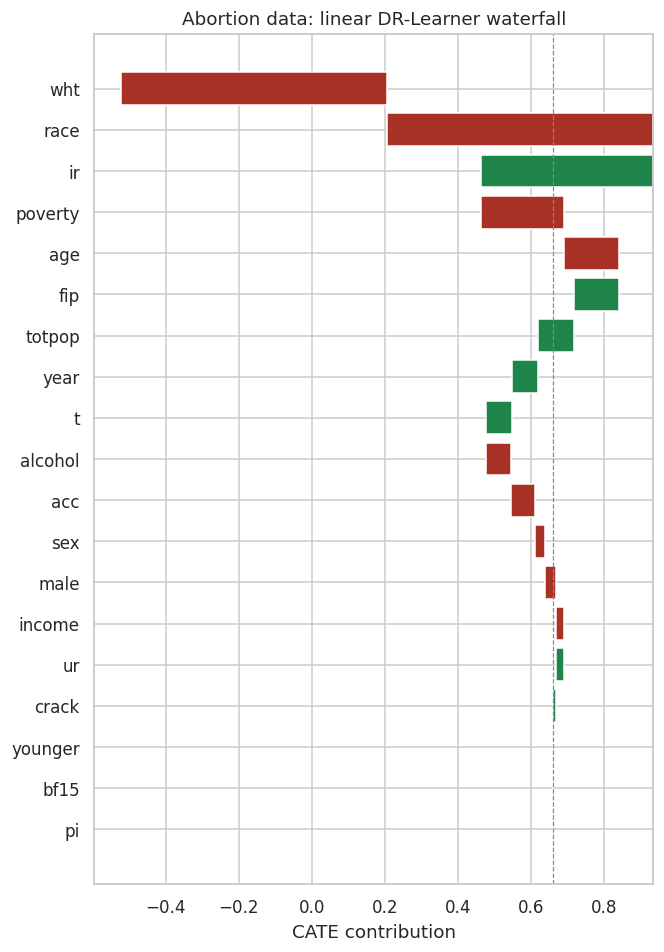

In [14]:
ab_exp.plot_importance(title="Abortion data: linear DR-Learner SHAP")
plt.show()
ab_exp.plot_waterfall(row=0, title="Abortion data: linear DR-Learner waterfall")
plt.show()


CATE is **Treated minus Control** on the log outcome scale for this encoding; intervals follow the package’s DR ATE routine (see `estimate_ate.DRLearner`).

### Summary and Conclusions

- **DR learners** in **PyCausalML** (``pycausalml.meta_learners``) implement cross-fitted, doubly robust meta-learning with several **final-stage** choices: forests (`ForestDRLearner`), OLS (`LinearDRLearner`), Lasso (`SparseLinearDRLearner`), and XGBoost (`XGBDRLearner`), or a fully custom mix via **`DRLearner()`**.
- **DML** (``pycausalml.double_machine_learning``) residualizes $Y$ and $T$ (or vector $T$) and fits a **second-stage** model for heterogeneous effects; **`CausalForestDML`** connects that pipeline to **grf**.
- Use **`estimate_ate()`** for a simple average effect summary with analytic (or bootstrap) uncertainty on the DR side; DML dispatch provides its own ATE helper.

**References**: Kennedy (2020) [[45]]; Foster et al. (2019); Chernozhukov et al. (2018) for DML. **EconML**: [DR](https://www.pywhy.org/EconML/spec/estimation/dr.html), [DML](https://www.pywhy.org/EconML/spec/estimation/dml.html).

## References

- PyCausalML source: ``pycausalml.meta_learners`` (DR learners), ``pycausalml.double_machine_learning`` (DML)
- [EconML DR spec](https://www.pywhy.org/EconML/spec/estimation/dr.html)
- [EconML DML spec](https://www.pywhy.org/EconML/spec/estimation/dml.html)
- Kennedy, E. H. (2020). *Optimal doubly robust estimation of heterogeneous causal effects*. arXiv:2004.14497.
- Chernozhukov, V., et al. (2018). *Double/debiased machine learning for treatment and structural parameters*. The Econometrics Journal.
- [generalized random forests](https://grf-labs.github.io/grf/)
- [`DoubleML` R](https://docs.doubleml.org/r/stable/)
